# Figure S2a–d — HBCA stripped-nuclei embeddings

Source: `NKT_tmp/draw_umap_breast.ipynb`; Supplementary Information, pages 5-6.
Read saved `X_umap`, `level2` and cell barcodes. Align selection status by barcode instead of transferring row positions between methods.
PARE is named Lasso-ARE in the source files. Here, refinement / woLasso refers to Lasso-View selection rectification,
which is distinct from the latent-refinement training workflow in Figure 5.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [3]:
FIGURE = 'figS2'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
    'original': 'pub_epithelial_pca500.h5ad',
    'PARE': 'new_evaluations/new_scRNA/data/reclustered_adata_test_42_rsc_releiden_downstream.h5ad',
    'PARE_woLasso': 'new_evaluations/new_scRNA/data/reclustered_adata_test_woLasso_42_rsc_releiden_downstream.h5ad',
    'scNET': 'new_evaluations/new_scRNA/data/scNET_breast_downstream.h5ad',
    'scFoundation': 'other_approaches/scFoundation/do_foundation_breast/scFoundation_breast.h5ad',
    'scVI': 'new_evaluations/new_scRNA/data/scvi_NK_releiden_downstream.h5ad',
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
Data root: /home/zzj/lare
  OK original: /home/zzj/lare/pub_epithelial_pca500.h5ad
  OK PARE: /home/zzj/lare/new_evaluations/new_scRNA/data/reclustered_adata_test_42_rsc_releiden_downstream.h5ad
  OK PARE_woLasso: /home/zzj/lare/new_evaluations/new_scRNA/data/reclustered_adata_test_woLasso_42_rsc_releiden_downstream.h5ad
  OK scNET: /home/zzj/lare/new_evaluations/new_scRNA/data/scNET_breast_downstream.h5ad
  OK scFoundation: /home/zzj/lare/other_approaches/scFoundation/do_foundation_breast/scFoundation_breast.h5ad
  OK scVI: /home/zzj/lare/new_evaluations/new_scRNA/data/scvi_NK_releiden_downstream.h5ad
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS2


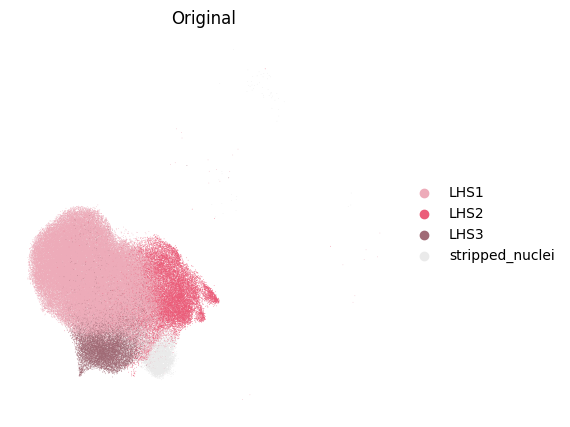

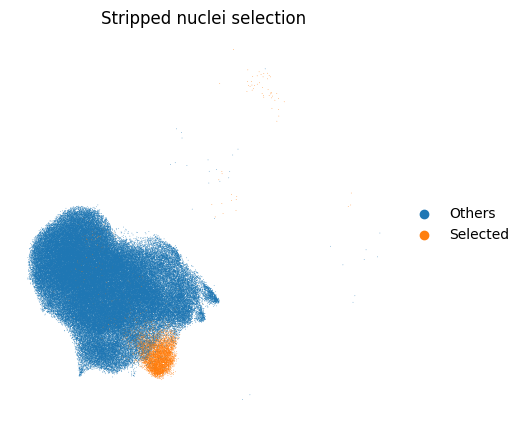

In [4]:
ORIGINAL = DATA_PATHS['original']
METHOD_PATHS = {
    'PARE': DATA_PATHS['PARE'],
    'PARE_woLasso': DATA_PATHS['PARE_woLasso'],
    'scNET': DATA_PATHS['scNET'],
    'scFoundation': DATA_PATHS['scFoundation'],
    'scVI': DATA_PATHS['scVI'],
}
reference = read_metadata(ORIGINAL)
mask = selection_mask(INPUT_DIR / 'figS1/hbca_stripped_selected.txt', reference.n_obs)
selected_barcodes = reference.obs_names[mask]
if not reference.obs_names.is_unique:
    raise ValueError('Reference cell barcodes are not unique')
set_selection(reference, mask)
for color, stem, title in [('level2', 'figS2a_original', 'Original'),
                           ('selection', 'figS2b_selection', 'Stripped nuclei selection')]:
    ax = plot_embedding(reference, color, title=title)
    save_figure(ax.figure, OUTPUT_DIR, stem)

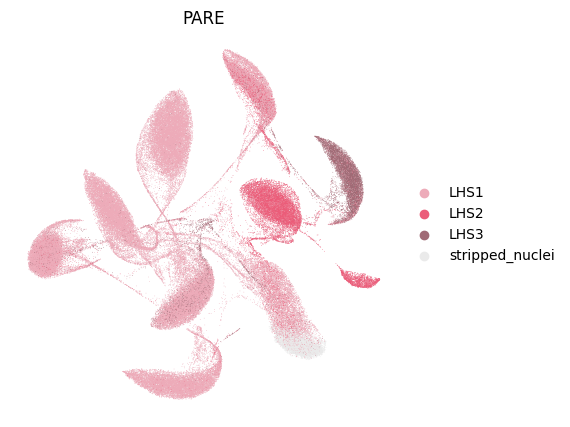

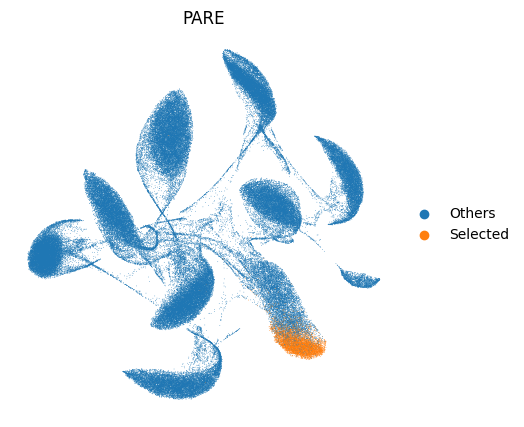

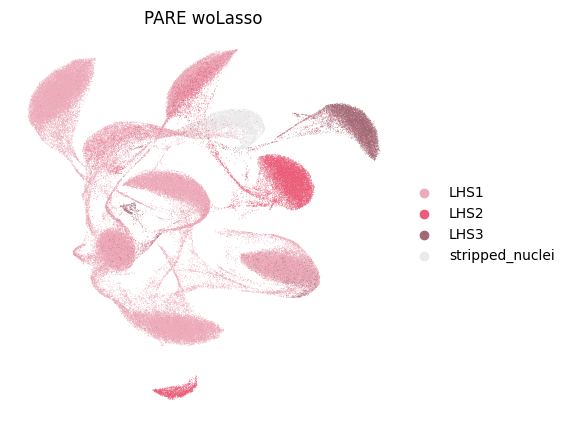

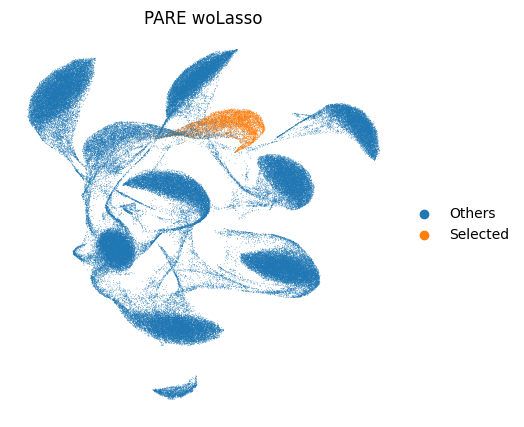

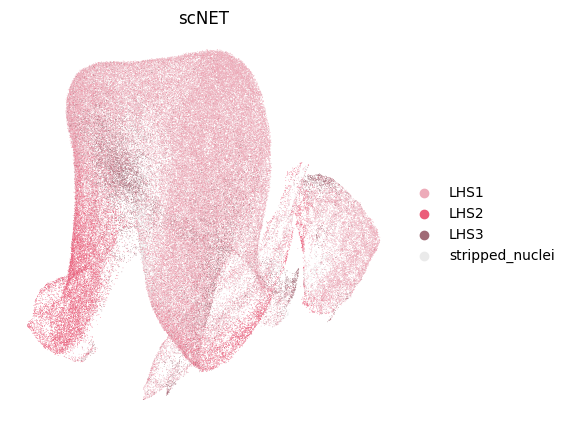

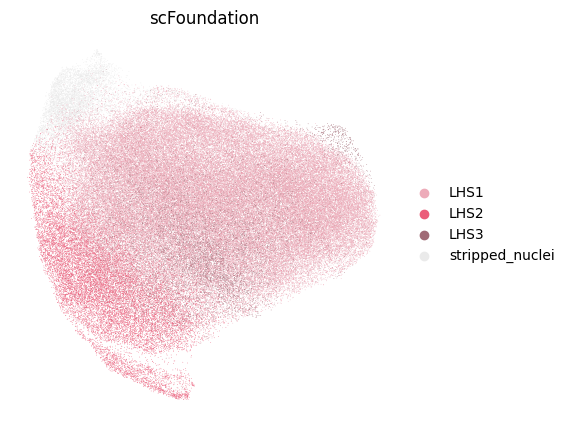

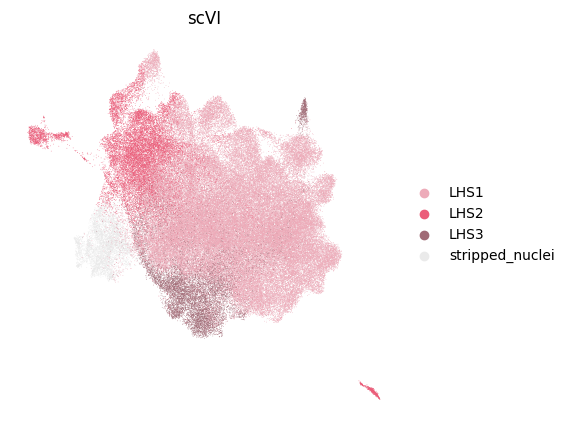

In [5]:
for method, path in METHOD_PATHS.items():
    adata = read_metadata(path)
    if not adata.obs_names.is_unique or not adata.obs_names.isin(reference.obs_names).all():
        raise ValueError(f'{method}: duplicated or unmatched cell barcodes')
    adata.obs['level2'] = reference.obs['level2'].reindex(adata.obs_names)
    if 'level2_colors' in reference.uns:
        adata.uns['level2_colors'] = reference.uns['level2_colors']
    set_selection(adata, adata.obs_names.isin(selected_barcodes))
    colors = ['level2', 'selection'] if method.startswith('PARE') else ['level2']
    panel = 'c' if method.startswith('PARE') else 'd'
    for color in colors:
        ax = plot_embedding(adata, color, title=method.replace('_', ' '))
        save_figure(ax.figure, OUTPUT_DIR, f'figS2{panel}_{method}_{color}')
    del adata